# Search-09c — Discrépance combinatoire : colorier ±1 sans déséquilibrer

**Navigation** : [Partie 1](README.md) | [Version Python](Search-09c-CombinatorialDiscrepancy.ipynb) | [Search-09d — Beck–Fiala en Lean](Search-09d-BeckFiala-Lean-Python.ipynb)

**Objectifs** : mesurer la discrépance de systèmes d'ensembles ; construire l'arrondi flottant de Beck–Fiala ; confronter sa borne à un oracle CP-SAT ; distinguer résultats prouvés et conjectures. **Prérequis** : matrices, algèbre linéaire, probabilités et optimisation. **Durée estimée** : 90 minutes.

La discrépance $\min_{x\in\{-1,+1\}^n}\|Ax\|_\infty$ mesure le pire déséquilibre de sommes ; elle diffère du nombre d'écarts à l'heuristique en [Limited Discrepancy Search](Search-03c-LimitedDiscrepancySearch.ipynb). Les bornes inférieures $\Omega(\sqrt{k})$ concernent certains systèmes dans le pire cas, pas chaque instance.

In [1]:
// MathNet fournit la vraie SVD ; OR-Tools résout les modèles CP-SAT natifs.
// La culture invariante assure des nombres SVG portables entre environnements.
#r "nuget: MathNet.Numerics, 5.0.0"
#r "nuget: Google.OrTools, 9.15.6755"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using Google.OrTools.Sat;
using MathNet.Numerics.LinearAlgebra.Double;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
Console.WriteLine($"Runtime {System.Runtime.InteropServices.RuntimeInformation.FrameworkDescription} ; MathNet {typeof(DenseMatrix).Assembly.GetName().Version} ; OR-Tools {typeof(CpModel).Assembly.GetName().Version}");


Installed Packages Google.OrTools, 9.15.6755 MathNet.Numerics, 5.0.0

Runtime .NET 10.0.14 ; MathNet 5.0.0.0 ; OR-Tools 9.15.6755.0


## 2. Définitions et appareil de mesure

Chaque colonne de la matrice d'incidence choisit $k$ lignes sans remise. Le degré est le maximum des sommes par colonne. Pour les petites instances, l'énumération des $2^n$ coloriages constitue un oracle indépendant.

In [2]:
// Chaque colonne du système appartient à k lignes distinctes ; la discrépance est le maximum absolu des sommes.
// L’énumération des signes sert d’oracle exact seulement pour les petites dimensions.
int[, ] Systeme(int n, int m, int k, Random rng)
{
    var a = new int[m, n];
    for (int i = 0; i < n; i++)
    {
        var lignes = Enumerable.Range(0, m).ToArray();
        for (int j = 0; j < Math.Min(k, m); j++)
        {
            int t = rng.Next(j, m);
            (lignes[j], lignes[t]) = (lignes[t], lignes[j]);
            a[lignes[j], i] = 1;
        }
    }

    return a;
}

int Degre(int[, ] a)
{
    int m = a.GetLength(0), n = a.GetLength(1), max = 0;
    for (int i = 0; i < n; i++)
    {
        int s = 0;
        for (int j = 0; j < m; j++)
            s += a[j, i];
        max = Math.Max(max, s);
    }

    return max;
}

int Disc(int[, ] a, int[] x)
{
    int m = a.GetLength(0), n = a.GetLength(1), max = 0;
    for (int j = 0; j < m; j++)
    {
        int s = 0;
        for (int i = 0; i < n; i++)
            s += a[j, i] * x[i];
        max = Math.Max(max, Math.Abs(s));
    }

    return max;
}

int ExactBrut(int[, ] a)
{
    int n = a.GetLength(1);
    if (n > 12)
        throw new ArgumentException("Enumeration limitée à 12 éléments");
    int best = int.MaxValue;
    for (int mask = 0; mask < (1 << n); mask++)
    {
        var x = Enumerable.Range(0, n).Select(i => (mask & (1 << i)) == 0 ? -1 : 1).ToArray();
        best = Math.Min(best, Disc(a, x));
    }

    return best;
}

var reference = Systeme(10, 6, 3, new Random(7));
Console.WriteLine("Matrice d'incidence :");
for (int j = 0; j < 6; j++)
    Console.WriteLine(string.Join(" ", Enumerable.Range(0, 10).Select(i => reference[j, i])));
Console.WriteLine($"Degré {Degre(reference)} ; optimum par 1024 coloriages : {ExactBrut(reference)}");


Matrice d'incidence :


0 1 1 1 0 0 0 1 0 1


0 0 1 0 1 0 1 1 1 0


1 1 0 0 1 1 0 0 1 0


0 0 0 1 0 1 0 1 0 1


1 1 0 0 0 0 1 0 0 1


1 0 1 1 1 1 1 0 1 0


Degré 3 ; optimum par 1024 coloriages : 1


### Lecture du résultat

Chaque ligne représente un ensemble ; chaque colonne appartient à trois ensembles. L'optimum est obtenu par énumération, sans hypothèse sur une borne asymptotique.

## 3. Le hasard pur et les bornes de pire cas

Mesurons 4 000 coloriages uniformes indépendants sur $n=m=60$, $k=12$. Les maxima sur plusieurs lignes peuvent dépasser l'échelle $\sqrt{k}$ d'une seule somme. Les bornes de type Erdős–Spencer affirment l'existence de systèmes difficiles ; elles ne constituent pas un plancher pour le système particulier observé. Sur cette instance le degré est 3 et l’énumération donne une discrépance optimale de 1.

In [3]:
// Les redémarrages testent des coloriages indépendants et retiennent le meilleur résultat mesuré.
// Les quantiles décrivent la dispersion du hasard sans fournir l’optimum du système.
(int, int[]) Meilleur(int[, ] a, Random r, int essais)
{
    int n = a.GetLength(1), best = int.MaxValue;
    int[] couleur = null;
    for (int t = 0; t < essais; t++)
    {
        var x = Enumerable.Range(0, n).Select(_ => r.Next(2) == 0 ? -1 : 1).ToArray();
        int d = Disc(a, x);
        if (d < best)
        {
            best = d;
            couleur = x;
        }
    }

    return (best, couleur);
}

var regulier = Systeme(60, 60, 12, new Random(11));
var rng = new Random(3);
int[] dist = Enumerable.Range(0, 4000).Select(_ => Meilleur(regulier, rng, 1).Item1).ToArray();
double Quantile(double[] a, double q)
{
    var v = a.OrderBy(x => x).ToArray();
    double z = (v.Length - 1) * q;
    int i = (int)z;
    return v[i] + (v[Math.Min(i + 1, v.Length - 1)] - v[i]) * (z - i);
}

Console.WriteLine($"4000 coloriages : médiane {Quantile(dist.Select(v => (double)v).ToArray(), .5):F1}, q90 {Quantile(dist.Select(v => (double)v).ToArray(), .9):F1}, q99,9 {Quantile(dist.Select(v => (double)v).ToArray(), .999):F1} ; √k={Math.Sqrt(12):F2}");
foreach (var g in dist.GroupBy(x => x).OrderBy(g => g.Key))
    Console.WriteLine($"disc={g.Key, 2} : {g.Count()}");


4000 coloriages : médiane 8.0, q90 11.0, q99,9 15.0 ; √k=3.46


disc= 5 : 9


disc= 6 : 210


disc= 7 : 702


disc= 8 : 1128


disc= 9 : 827


... (4 outputs left out)

disc=14 : 21


disc=15 : 5


disc=16 : 2


disc=17 : 1


### Lecture du résultat

La distribution rapporte le maximum sur les lignes de la matrice à chaque tirage, pas l'optimum du système. Les quantiles résument la variabilité du hasard.

### Exercice 1 — Redémarrages aléatoires

Mesurez le meilleur résultat pour chaque nombre d'essais $T$. Incluez $T=1$ ; la formule heuristique $\sqrt{k}\sqrt{\log(m)/\log T}$ n'est définie que pour $T>1$. Utilisez les graines fournies pour comparer les résultats. Ici la médiane vaut 8 et les quantiles 90 % et 99,9 % valent 11 et 15.

In [4]:
Dictionary<int, int> Redemarrages(int[, ] a, int[] tailles, int seed)
{
    return null;
} // TODO : Meilleur(a, new Random(seed), T) pour chaque T

var testR = Systeme(8, 6, 2, new Random(14));
var ts = new[]
{
    1,
    10,
    100
};
var r1 = Redemarrages(testR, ts, 5);
if (r1 is null)
    Console.WriteLine("Exercice 1 à compléter : redémarrages");
else
{
    if (r1.Count != ts.Length || ts.Any(t => !r1.ContainsKey(t) || r1[t] != Meilleur(testR, new Random(5), t).Item1))
        throw new Exception("Redémarrages incorrects");
    var tailles = new[]
    {
        1,
        10,
        100,
        1000,
        10000
    };
    var reel = Redemarrages(regulier, tailles, 5);
    if (reel is null)
        throw new Exception("Exercice 1 : réponse partielle sur budgets réels");
    else
    {
        if (reel.Count != tailles.Length || tailles.Any(t => !reel.ContainsKey(t) || reel[t] != Meilleur(regulier, new Random(5), t).Item1))
            throw new Exception("Redémarrages incorrects sur le système réel");
        foreach (int t in tailles)
            Console.WriteLine($"T={t, 5} : meilleure discrépance {reel[t]} ; échelle {(t == 1 ? "indéfinie" : (Math.Sqrt(12) * Math.Sqrt(Math.Log(60) / Math.Log(t))).ToString("F3"))}");
        var courbe = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='400' viewBox='0 0 700 400'><rect width='700' height='400' fill='white'/><text x='350' y='25' text-anchor='middle'>Meilleur coloriage selon les redémarrages</text><line x1='75' y1='330' x2='655' y2='330' stroke='black'/><line x1='75' y1='55' x2='75' y2='330' stroke='black'/><text x='18' y='195' transform='rotate(-90 18 195)' text-anchor='middle'>discrépance / échelle</text>");
        double ymax = Math.Ceiling(Math.Max(reel.Values.Max(), tailles.Skip(1).Max(t => Math.Sqrt(12) * Math.Sqrt(Math.Log(60) / Math.Log(t)))) + 1);
        double YR(double v) => 330 - 260 * v / ymax;
        for (int tick = 0; tick <= ymax; tick += 2)
            courbe.Append($"<line x1='75' y1='{YR(tick):F1}' x2='655' y2='{YR(tick):F1}' stroke='#ddd'/><text x='65' y='{YR(tick) + 4:F1}' text-anchor='end'>{tick}</text>");
        var pts = tailles.Select((t, i) => (x: 110 + i * 130, y: YR(reel[t]))).ToArray();
        courbe.Append("<polyline fill='none' stroke='#4477aa' stroke-width='3' points='" + string.Join(" ", pts.Select(p => $"{p.x},{p.y:F1}")) + "'/>");
        foreach (var p in pts)
            courbe.Append($"<circle cx='{p.x}' cy='{p.y:F1}' r='4' fill='#4477aa'/>");
        var theor = tailles.Skip(1).Select((t, i) => (x: 240 + i * 130, y: YR(Math.Sqrt(12) * Math.Sqrt(Math.Log(60) / Math.Log(t))))).ToArray();
        courbe.Append("<polyline fill='none' stroke='#aa3377' stroke-width='3' stroke-dasharray='5 4' points='" + string.Join(" ", theor.Select(p => $"{p.x},{p.y:F1}")) + "'/>");
        for (int i = 0; i < tailles.Length; i++)
            courbe.Append($"<text x='{110 + i * 130}' y='350' text-anchor='middle'>{tailles[i]}</text>");
        courbe.Append("<text x='350' y='371' text-anchor='middle'>nombre de tirages T (échelle logarithmique)</text><rect x='100' y='380' width='12' height='12' fill='#4477aa'/><text x='118' y='391'>meilleur observé</text><rect x='350' y='380' width='12' height='12' fill='#aa3377'/><text x='368' y='391'>échelle heuristique, T&gt;1</text></svg>");
        Microsoft.DotNet.Interactive.Formatting.Formatter.Register<CourbeSvg>((value, context) =>
        {
            context.Writer.Write(value.Content);
            return true;
        }, "image/svg+xml");
        Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(typeof(CourbeSvg), new[] { "image/svg+xml" });
        display(new CourbeSvg(courbe.ToString()));
    }
}

record CourbeSvg(string Content);


Exercice 1 à compléter : redémarrages


## 4. Beck–Fiala : arrondi flottant et noyau

Une ligne est active quand elle contient **plus de $k$ flottants**. Comme chaque colonne appartient à au plus $k$ lignes, le nombre d'équations actives est strictement inférieur au nombre de flottants. Une direction non nulle du noyau existe. On avance jusqu'à ce qu'une variable atteigne $-1$ ou $+1$, en vérifiant le résidu et la progression. Le cas $k=0$ est traité directement. Pour des incidences 0/1 de degré $k>0$, la garantie classique est $2k-1$.

In [5]:
// L’arrondi flottant protège les lignes qui contiennent strictement plus de k coordonnées flottantes.
// La direction SVD doit appartenir au noyau actif ; chaque phase fixe au moins une coordonnée.
(int[], int) BeckFiala(int[, ] a)
{
    int m = a.GetLength(0), n = a.GetLength(1), k = Degre(a);
    if (k == 0)
        return (Enumerable.Repeat(1, n).ToArray(), 0);
    var x = new double[n];
    var f = Enumerable.Repeat(true, n).ToArray();
    int phases = 0;
    while (f.Any(v => v))
    {
        var ids = Enumerable.Range(0, n).Where(i => f[i]).ToArray();
        var rows = Enumerable.Range(0, m).Where(j => ids.Sum(i => a[j, i]) > k).ToArray();
        double[] u;
        if (rows.Length == 0)
            u = Enumerable.Repeat(1.0, ids.Length).ToArray();
        else
        {
            var af = DenseMatrix.Create(rows.Length, ids.Length, (j, i) => a[rows[j], ids[i]]);
            var svd = af.Svd(true);
            var vec = svd.VT.Row(ids.Length - 1);
            double residu = (af * vec).L2Norm();
            if (residu > 1e-9 * Math.Max(1.0, af.FrobeniusNorm()))
                throw new Exception("Direction hors du noyau");
            u = vec.ToArray();
        }

        double pas = double.PositiveInfinity;
        for (int j = 0; j < ids.Length; j++)
        {
            double v = u[j], xi = x[ids[j]];
            if (v > 1e-12)
                pas = Math.Min(pas, (1 - xi) / v);
            else if (v < -1e-12)
                pas = Math.Min(pas, (-1 - xi) / v);
        }

        if (!double.IsFinite(pas) || pas <= 0)
            throw new Exception("Pas de figeage invalide");
        for (int j = 0; j < ids.Length; j++)
            x[ids[j]] += pas * u[j];
        int touches = 0;
        foreach (int i in ids)
            if (Math.Abs(Math.Abs(x[i]) - 1) < 1e-9)
            {
                x[i] = x[i] >= 0 ? 1 : -1;
                f[i] = false;
                touches++;
            }

        if (touches == 0)
            throw new Exception("Aucune variable figée");
        phases++;
    }

    return (x.Select(v => v >= 0 ? 1 : -1).ToArray(), phases);
}

var identite = new int[4, 4];
for (int i = 0; i < 4; i++)
    identite[i, i] = 1;
var probe = BeckFiala(identite);
if (Disc(identite, probe.Item1) != 1)
    throw new Exception("Contre-exemple identité invalide");
var zero = new int[3, 4];
if (Disc(zero, BeckFiala(zero).Item1) != 0)
    throw new Exception("Cas k=0 invalide");
Console.WriteLine("I₄ (k=1) et matrice nulle (k=0) vérifiées.");
Console.WriteLine(" n  m  k | BF | borne | meilleur aléatoire | phases");
var bf40 = new List<int>();
var rand40 = new List<int>();
for (int seed = 0; seed < 6; seed++)
{
    var a = Systeme(40, 30, 5, new Random(100 + seed));
    var(x, ph) = BeckFiala(a);
    int d = Disc(a, x), b = 2 * Degre(a) - 1, dr = Meilleur(a, new Random(seed), 500).Item1;
    if (d > b || ph > 40)
        throw new Exception("Garantie BF violée");
    bf40.Add(d);
    rand40.Add(dr);
    Console.WriteLine($"40 30  {Degre(a)} | {d, 2} | {b, 5} | {dr, 18} | {ph, 6}");
}


I₄ (k=1) et matrice nulle (k=0) vérifiées.


 n  m  k | BF | borne | meilleur aléatoire | phases


40 30  5 |  6 |     9 |                  3 |     40


40 30  5 |  6 |     9 |                  3 |     40


40 30  5 |  7 |     9 |                  3 |     40


40 30  5 |  7 |     9 |                  3 |     40


40 30  5 |  6 |     9 |                  2 |     40


40 30  5 |  7 |     9 |                  3 |     40


### Lecture du résultat

Les six instances vérifient la borne $2k-1$ et la limite de phases ; le meilleur de 500 tirages peut être plus petit sans fournir cette garantie de pire cas. La matrice identité donne un contre-exemple à la règle erronée « actives si au moins $k$ flottants » : elle produirait une matrice active de rang plein.

## 5. La frontière théorique

Les énoncés suivants sont **cités**, sauf la ligne Beck–Fiala mesurée dans le banc ; les résolutions de 2026 restent **annoncées**, non revues par les pairs.

| Résultat | Borne et statut |
|---|---|
| Beck–Fiala (1981) | $2k-1$ : théorème et arrondi mesuré ici pour les incidences 0/1. |
| Banaszczyk (1998) | $O(\sqrt{k\log n})$ : résultat cité. |
| Bansal–Jiang (2025) | $O(\sqrt{k})$ si $k\geq\log^2 n$ ; $\tilde O(\sqrt{k}+\sqrt{\log n})$ en dessous : résultats cités. |
| Spencer (1985) | $O(\sqrt n)$ si $m=n$ : résultat cité. |
| Komlós, colonnes unitaires | $O(\sqrt{\log n})$ par Banaszczyk ; $\tilde O(\log^{1/4} n)$ en 2025 : résultats cités. |
| Guo–Fang–Lu (2026) | $<3\sqrt{2\pi}$ pour Komlós et $<3\sqrt{2\pi k}$ pour Beck–Fiala : préprint annoncé, non revu. |

La conjecture de Beck–Fiala demande une garantie $O(\sqrt{k})$ dans le pire cas ; Komlós concerne des colonnes réelles unitaires et non seulement des incidences 0/1. Sur ce banc, Beck–Fiala rend 6 ou 7 pour une borne de 9 ; le meilleur de 500 tirages rend 2 ou 3.

## 6. CP-SAT en oracle exact

Pour $x_i=2b_i-1$, minimiser $D$ sous $-D\leq (Ax)_j\leq D$. Seul le statut `Optimal` certifie l'optimum ; un statut `Feasible` n'est qu'une borne supérieure. Huit instances $n=12,m=10,k=4$ sont confrontées à Beck–Fiala et au meilleur de 300 coloriages, avec 10 secondes au plus par résolution.

In [6]:
// Une variable binaire encode chaque signe ; les sommes de lignes sont bornées par la discrépance minimisée.
// Le statut et la borne restent distincts d’une preuve d’optimalité quand le budget expire.
(int? , string) ExactCp(int[, ] a, double limite = 10)
{
    int m = a.GetLength(0), n = a.GetLength(1);
    var model = new CpModel();
    var x = Enumerable.Range(0, n).Select(i => model.NewBoolVar($"b{i}")).ToArray();
    var d = model.NewIntVar(0, n, "D");
    for (int j = 0; j < m; j++)
    {
        var ids = Enumerable.Range(0, n).Where(i => a[j, i] != 0).ToArray();
        LinearExpr somme = LinearExpr.Sum(ids.Select(i => x[i]));
        model.Add(2 * somme - ids.Length <= d);
        model.Add(2 * somme - ids.Length >= -d);
    }

    model.Minimize(d);
    var solver = new CpSolver
    {
        StringParameters = $"max_time_in_seconds:{limite.ToString(CultureInfo.InvariantCulture)} num_search_workers:1"};
    var status = solver.Solve(model);
    return (status == CpSolverStatus.Optimal ? (int? )solver.Value(d) : null, status.ToString());
}

var comparaisons = new List<(int exact, int bf, int alea)>();
Console.WriteLine("n  k | CP-SAT statut | BF | 2k-1 | aléatoire | écart BF/optimal");
for (int seed = 0; seed < 8; seed++)
{
    var a = Systeme(12, 10, 4, new Random(200 + seed));
    var(exact, st) = ExactCp(a);
    var(x, ph) = BeckFiala(a);
    int bf = Disc(a, x), alea = Meilleur(a, new Random(seed), 300).Item1;
    if (exact.HasValue)
    {
        int brute = ExactBrut(a);
        if (exact.Value != brute || bf < exact || bf > 2 * Degre(a) - 1)
            throw new Exception("Incohérence oracle");
        comparaisons.Add((exact.Value, bf, alea));
        Console.WriteLine($"12  4 | {exact, 6} {st, -7} | {bf, 2} | {2 * Degre(a) - 1, 4} | {alea, 9} | {bf - exact, 5:+0;-0;0}");
    }
    else
        Console.WriteLine($"12  4 | pas d'optimum prouvé ({st}) | {bf, 2} | {2 * Degre(a) - 1, 4} | {alea, 9}");
}

if (comparaisons.Count > 0)
    Console.WriteLine($"Écart moyen BF/optimum sur {comparaisons.Count} instances prouvées : {comparaisons.Average(v => v.bf - v.exact):F2}");


n  k | CP-SAT statut | BF | 2k-1 | aléatoire | écart BF/optimal


12  4 |      1 Optimal |  5 |    7 |         1 |    +4


12  4 |      1 Optimal |  4 |    7 |         1 |    +3


12  4 |      1 Optimal |  6 |    7 |         1 |    +5


12  4 |      1 Optimal |  6 |    7 |         1 |    +5


12  4 |      1 Optimal |  5 |    7 |         2 |    +4


12  4 |      1 Optimal |  5 |    7 |         1 |    +4


12  4 |      1 Optimal |  4 |    7 |         2 |    +3


12  4 |      1 Optimal |  5 |    7 |         1 |    +4


Écart moyen BF/optimum sur 8 instances prouvées : 4.00


### Lecture du résultat

Chaque optimum CP-SAT prouvé est aussi comparé à l'énumération exhaustive des $2^{12}$ coloriages. Le tableau sépare l'écart algorithmique à l'optimum de la borne de pire cas $2k-1$.

### Exercice 2 — Le cas dense de Spencer

Générez pour chaque taille un système carré avec exactement $\lfloor n/2\rfloor$ éléments par ligne, à l'aide de `DenseSysteme`. Appelez l'oracle fourni sur chaque matrice. Comparez les résultats observés à $\sqrt n$ : quelques instances ne prouvent ni monotonie ni croissance asymptotique. Beck–Fiala reste applicable à une incidence dense, mais sa borne de degré peut être peu informative. Les huit optima prouvés valent 1 ; l’écart moyen observé avec Beck–Fiala vaut 4,00.

In [7]:
// Les matrices denses changent l’échelle de la question de Spencer.
// Le callback observé oblige l’exercice à invoquer réellement l’oracle pour chaque taille.
int[, ] DenseSysteme(int n, Random r)
{
    var a = new int[n, n];
    for (int j = 0; j < n; j++)
    {
        var ordre = Enumerable.Range(0, n).ToArray();
        for (int k = 0; k < n / 2; k++)
        {
            int t = r.Next(k, n);
            (ordre[k], ordre[t]) = (ordre[t], ordre[k]);
            a[j, ordre[k]] = 1;
        }
    }

    return a;
}

Dictionary<int, int?> Spencer(int[] tailles, int seed, Func<int[, ], int?> oracle)
{
    return null;
} // TODO : construire chaque matrice et appeler l'oracle

(bool, Dictionary<int, int?>) TesterSpencer(int[] tailles, int seed)
{
    var attendu = new Dictionary<int, int[, ]>();
    var rngD = new Random(seed);
    foreach (int n in tailles)
        attendu[n] = DenseSysteme(n, rngD);
    var vus = new Dictionary<int, int?>();
    int? Observe(int[, ] a)
    {
        int n = a.GetLength(0);
        if (!attendu.ContainsKey(n) || a.GetLength(1) != n || vus.ContainsKey(n))
            throw new Exception("Matrice dense inattendue");
        for (int j = 0; j < n; j++)
            for (int i = 0; i < n; i++)
                if (a[j, i] != attendu[n][j, i])
                    throw new Exception("Matrice dense différente");
        var res = ExactCp(a).Item1;
        vus[n] = res;
        return res;
    }

    var rep = Spencer(tailles, seed, Observe);
    if (rep is null)
        return (false, null);
    if (rep.Count != tailles.Length || vus.Count != tailles.Length || tailles.Any(n => !rep.ContainsKey(n) || rep[n] != vus[n]))
        throw new Exception("Spencer : oracle non appelé ou valeur incorrecte");
    return (true, rep);
}

var testS = TesterSpencer(new[] { 4, 6 }, 9);
if (!testS.Item1)
    Console.WriteLine("Exercice 2 à compléter : systèmes denses");
else
{
    var reel = TesterSpencer(new[] { 10, 12, 14 }, 42);
    if (!reel.Item1)
        throw new Exception("Exercice 2 : réponse partielle sur tailles réelles");
    else
        foreach (var kv in reel.Item2)
            Console.WriteLine($"n={kv.Key} : optimum {(kv.Value.HasValue ? kv.Value.ToString() : "non prouvé")}, √n={Math.Sqrt(kv.Key):F2}, d/√n={(kv.Value.HasValue ? (kv.Value.Value / Math.Sqrt(kv.Key)).ToString("F3") : "non disponible")}");
}


Exercice 2 à compléter : systèmes denses


## 7. Une expérience Komlós à colonnes unitaires

Pour une matrice réelle, la discrépance reste $\|Ax\|_\infty$ mais le degré d'incidence 0/1 n'est plus le paramètre du théorème Beck–Fiala. L'adaptation flottante ci-dessous retient les lignes ayant plus de $m/2$ coefficients flottants non nuls, en limitant leur nombre à une de moins que les variables flottantes, de façon à conserver une direction de noyau. C'est une expérience, sans transfert de la garantie $2k-1$.

In [8]:
// Les colonnes réelles sont normalisées puis un arrondi numérique est comparé au hasard.
// Ce banc sur vecteurs réels est distinct de la garantie Beck–Fiala pour matrices d’incidence.
double DiscReelle(double[, ] a, int[] x)
{
    double max = 0;
    for (int j = 0; j < a.GetLength(0); j++)
    {
        double s = 0;
        for (int i = 0; i < a.GetLength(1); i++)
            s += a[j, i] * x[i];
        max = Math.Max(max, Math.Abs(s));
    }

    return max;
}

int[] ArrondiReel(double[, ] a)
{
    int m = a.GetLength(0), n = a.GetLength(1);
    var x = new double[n];
    var libre = Enumerable.Repeat(true, n).ToArray();
    while (libre.Any(v => v))
    {
        var ids = Enumerable.Range(0, n).Where(i => libre[i]).ToArray();
        var rows = Enumerable.Range(0, m).Where(j => ids.Count(i => Math.Abs(a[j, i]) > 1e-12) > m / 2).Take(ids.Length - 1).ToArray();
        int r = rows.Length;
        double[] u;
        if (r == 0)
            u = Enumerable.Repeat(1.0, ids.Length).ToArray();
        else
        {
            var af = DenseMatrix.Create(r, ids.Length, (j, i) => a[rows[j], ids[i]]);
            var v = af.Svd(true).VT.Row(ids.Length - 1);
            if ((af * v).L2Norm() > 1e-9 * Math.Max(1, af.FrobeniusNorm()))
                throw new Exception("Noyau réel invalide");
            u = v.ToArray();
        }

        double pas = double.PositiveInfinity;
        for (int j = 0; j < ids.Length; j++)
        {
            double z = u[j];
            if (z > 1e-12)
                pas = Math.Min(pas, (1 - x[ids[j]]) / z);
            else if (z < -1e-12)
                pas = Math.Min(pas, (-1 - x[ids[j]]) / z);
        }

        if (!double.IsFinite(pas) || pas <= 0)
            throw new Exception("Pas réel invalide");
        for (int j = 0; j < ids.Length; j++)
            x[ids[j]] += pas * u[j];
        int touches = 0;
        foreach (int i in ids)
            if (Math.Abs(Math.Abs(x[i]) - 1) < 1e-9)
            {
                x[i] = x[i] >= 0 ? 1 : -1;
                libre[i] = false;
                touches++;
            }

        if (touches == 0)
            throw new Exception("Pas réel sans progrès");
    }

    return x.Select(v => v >= 0 ? 1 : -1).ToArray();
}

double MeilleurReel(double[, ] a, int essais, int seed)
{
    var rng = new Random(seed);
    double best = double.PositiveInfinity;
    for (int t = 0; t < essais; t++)
    {
        var x = Enumerable.Range(0, a.GetLength(1)).Select(_ => rng.Next(2) == 0 ? -1 : 1).ToArray();
        best = Math.Min(best, DiscReelle(a, x));
    }

    return best;
}

double[, ] ColonnesUnitaires(int m, int n, int seed)
{
    var r = new Random(seed);
    var a = new double[m, n];
    for (int i = 0; i < n; i++)
    {
        double norme = 0;
        for (int j = 0; j < m; j++)
        {
            double z = Math.Sqrt(-2 * Math.Log(1 - r.NextDouble())) * Math.Cos(2 * Math.PI * r.NextDouble());
            a[j, i] = z;
            norme += z * z;
        }

        norme = Math.Sqrt(norme);
        for (int j = 0; j < m; j++)
            a[j, i] /= norme;
    }

    return a;
}

Console.WriteLine("Matrice réelle, coloriages aléatoires et arrondi expérimental définis.");


Matrice réelle, coloriages aléatoires et arrondi expérimental définis.


### Exercice 3 — Komlós : comparer deux coloriages

Retournez la meilleure discrépance aléatoire et celle de l'arrondi réel fourni. Une fois les fixtures validées, comparez sur $m=8,n=40$ à $\sqrt{\log n}$, $\log^{1/4}n$ et la constante annoncée $3\sqrt{2\pi}$. L'arrondi réel est expérimental et ne porte pas la garantie d'incidence 0/1.

In [9]:
(double alea, double adapte)? Komlos(double[, ] a, int essais, int seed)
{
    return null;
} // TODO : MeilleurReel et DiscReelle(a, ArrondiReel(a))

bool VerifierKomlos((double alea, double adapte)? reponse, double[, ] a, int essais, int seed)
{
    if (!reponse.HasValue)
        return false;
    var v = reponse.Value;
    double ra = MeilleurReel(a, essais, seed), rb = DiscReelle(a, ArrondiReel(a));
    if (!double.IsFinite(v.alea) || !double.IsFinite(v.adapte) || Math.Abs(v.alea - ra) > 1e-9 || Math.Abs(v.adapte - rb) > 1e-9)
        throw new Exception("Comparaison Komlós incorrecte");
    return true;
}

var ka = ColonnesUnitaires(3, 6, 7);
var kb = ColonnesUnitaires(4, 7, 11);
var kr1 = Komlos(ka, 20, 42);
var kr2 = Komlos(kb, 30, 8);
bool k1 = VerifierKomlos(kr1, ka, 20, 42), k2 = VerifierKomlos(kr2, kb, 30, 8);
if (k1 != k2)
    throw new Exception("Exercice 3 : réponses partielles");
if (!k1 && !k2)
    Console.WriteLine("Exercice 3 à compléter : Komlós");
else
{
    var reel = ColonnesUnitaires(8, 40, 21);
    var res = Komlos(reel, 1000, 42);
    if (VerifierKomlos(res, reel, 1000, 42))
        Console.WriteLine($"Komlós 8×40 : hasard {res.Value.alea:F3}, arrondi {res.Value.adapte:F3} ; √log(n)={Math.Sqrt(Math.Log(40)):F3}, log(n)^¼={Math.Pow(Math.Log(40), .25):F3}, 3√(2π)={3 * Math.Sqrt(2 * Math.PI):F3}");
    else
        throw new Exception("Exercice 3 : réponse partielle sur 8×40");
}


Exercice 3 à compléter : Komlós


## 8. Exercices et visualisation

Les exercices répartis étudient les redémarrages, le cas dense et les colonnes unitaires. Le graphique résume les huit comparaisons où CP-SAT a prouvé l'optimum.

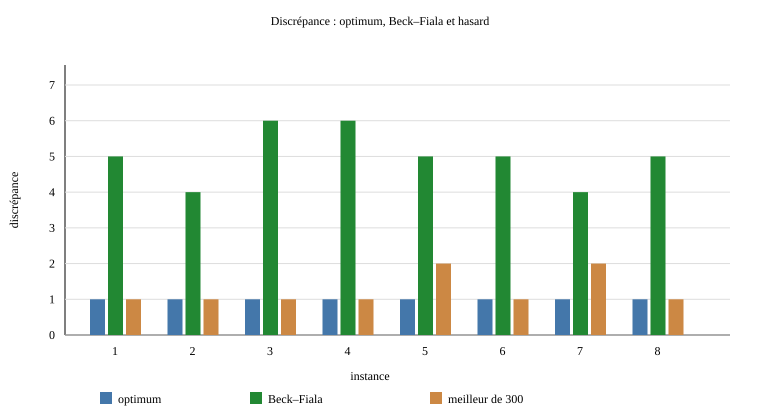

8 instances à optimum prouvé représentées.


In [10]:
// La figure compare uniquement les instances dont l’optimum est prouvé par le solveur.
// Chaque série conserve ses valeurs calculées et une légende propre.
record Svg(string Content);
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Svg>((value, context) =>
{
    context.Writer.Write(value.Content);
    return true;
}, "image/svg+xml");
Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(typeof(Svg), new[] { "image/svg+xml" });
if (comparaisons.Count == 0)
    Console.WriteLine("Aucun optimum prouvé à représenter.");
else
{
    int count = comparaisons.Count, max = comparaisons.Max(v => Math.Max(v.bf, Math.Max(v.exact, v.alea))) + 1;
    var svg = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='760' height='420' viewBox='0 0 760 420'><rect width='760' height='420' fill='white'/><text x='380' y='25' text-anchor='middle'>Discrépance : optimum, Beck–Fiala et hasard</text><line x1='65' y1='335' x2='730' y2='335' stroke='black'/><line x1='65' y1='65' x2='65' y2='335' stroke='black'/><text x='18' y='200' transform='rotate(-90 18 200)' text-anchor='middle'>discrépance</text>");
    for (int t = 0; t <= max; t++)
    {
        double y = 335 - 250.0 * t / max;
        svg.Append($"<line x1='65' y1='{y:F2}' x2='730' y2='{y:F2}' stroke='#ddd'/><text x='55' y='{y + 4:F2}' text-anchor='end'>{t}</text>");
    }

    for (int i = 0; i < count; i++)
    {
        double x = 90 + i * (620.0 / count);
        int[] vals =
        {
            comparaisons[i].exact,
            comparaisons[i].bf,
            comparaisons[i].alea
        };
        string[] colors =
        {
            "#4477aa",
            "#228833",
            "#cc8844"
        };
        for (int j = 0; j < 3; j++)
        {
            double hh = 250.0 * vals[j] / max;
            svg.Append($"<rect x='{x + j * 18:F2}' y='{335 - hh:F2}' width='15' height='{hh:F2}' fill='{colors[j]}'/>");
        }

        svg.Append($"<text x='{x + 25:F2}' y='355' text-anchor='middle'>{i + 1}</text>");
    }

    svg.Append("<text x='370' y='380' text-anchor='middle'>instance</text><rect x='100' y='392' width='12' height='12' fill='#4477aa'/><text x='118' y='403'>optimum</text><rect x='250' y='392' width='12' height='12' fill='#228833'/><text x='268' y='403'>Beck–Fiala</text><rect x='430' y='392' width='12' height='12' fill='#cc8844'/><text x='448' y='403'>meilleur de 300</text></svg>");
    display(new Svg(svg.ToString()));
    Console.WriteLine($"{count} instances à optimum prouvé représentées.");
}


### Lecture du résultat

Chaque groupe montre les trois discrépances sur une même instance ; l'optimum est une borne inférieure pour toute coloration faisable. Les essais aléatoires et l'arrondi ont des garanties différentes.

## À retenir

- Les bornes inférieures en $\Omega(\sqrt{k})$ décrivent certains systèmes difficiles ; elles ne s'appliquent pas comme plancher à chaque instance.
- Pour les incidences 0/1, l'arrondi flottant conserve les sommes des lignes actives et garantit $2k-1$ lorsque $k>0$.
- CP-SAT prouve l'optimum quand son statut est `Optimal` ; sa borne ne prouve pas un théorème général.

## Vérifiez votre compréhension

1. Pourquoi la direction de noyau existe-t-elle ?

<details><summary>Réponse</summary>
Les lignes actives contiennent plus de $k$ flottants alors que chaque colonne apparaît au plus $k$ fois. Elles sont donc strictement moins nombreuses que les flottants.
</details>

2. Pourquoi comparer à plusieurs essais aléatoires ?

<details><summary>Réponse</summary>
Cela mesure une méthode empirique différente ; ses bons résultats sur quelques instances ne fournissent pas la garantie de pire cas de Beck–Fiala.
</details>

3. Que signifie le statut `Optimal` de CP-SAT ?

<details><summary>Réponse</summary>
Il certifie l'optimum du modèle fini résolu, pas une borne universelle pour tous les systèmes.
</details>

## Pour aller plus loin

[Search-09d — Beck–Fiala en Lean](Search-09d-BeckFiala-Lean-Python.ipynb) ; [Bansal–Jiang (2025)](https://arxiv.org/abs/2508.03961) ; [Guo–Fang–Lu (2026), préprint non revu](https://arxiv.org/abs/2609.11189) ; Spencer (1985), *Six standard deviations suffice* ; Beck et Fiala (1981), *Integer-making theorems*.